## Cellpose-SAM: superhuman generalization for cellular segmentation

Marius Pachitariu, Michael Rariden, Carsen Stringer

[paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)

This notebook shows how to process your own 2D or 3D images, saved on Google Drive.

This notebook is adapted from the notebook by Pradeep Rajasekhar, inspired by the [ZeroCostDL4Mic notebook series](https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki).

### Make sure you have GPU access enabled by going to Runtime -> Change Runtime Type -> Hardware accelerator and selecting GPU

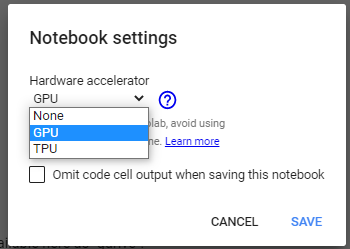

Check GPU and instantiate model - will download weights.

In [1]:
import numpy as np
from cellpose import models, core, io, plot, utils
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt
from natsort import natsorted

io.logger_setup() # run this to get printing of progress

#Check if colab notebook instance has GPU access
if core.use_gpu()==False:
  raise ImportError("No GPU access, change your runtime")

model = models.CellposeModel(pretrained_model='C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\models\\austen', gpu=True)

#model=models.CellposeModel(gpu=True)

### You can also use other pretrained models, like the DINO models 
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino")
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino-vitb")

[GUI INFO] : WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log

cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-14 20:54:58,249 [io INFO] WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log
2026-10-14 20:54:58,250 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-14 20:54:58,617 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-14 20:54:58,618 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-14 20:54:58,619 [core INFO] >>>> using GPU (CUDA)
2026-10-14 20:55:01,615 [models INFO] >>>> loading model C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\models\austen


Input directory with your images:

In [9]:
# *** change to your folder path ***
inputdir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\Visualization_austen_performance_no_test\\post-training\\not_out_of_focus"
inputdir = Path(inputdir)
outputdir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\Visualization_austen_performance_no_test\\post-training"
outputdir = Path(outputdir)

if not inputdir.exists():
  raise FileNotFoundError("directory does not exist")

# *** change to your image extension ***
image_ext = ".tif"

# list all files
files = natsorted([f for f in inputdir.glob("*"+image_ext) if "_masks" not in f.name and "_flows" not in f.name and "BU" not in f.name])

if(len(files)==0):
  raise FileNotFoundError("no image files found, did you specify the correct folder and extension?")
else:
  print(f"{len(files)} images in folder:")

for f in files:
  print(f.name)

1 images in folder:
m0_plate2_PointA5_R02_im_Composite_PC_DAPI_Seq0185_Dapi_8bit.tif


## Run Cellpose-SAM on one image in folder

Here are some of the parameters you can change:

* ***flow_threshold*** is  the  maximum  allowed  error  of  the  flows  for  each  mask.   The  default  is 0.4.
    *  **Increase** this threshold if cellpose is not returning as many masks as you’d expect (or turn off completely with 0.0)
    *   **Decrease** this threshold if cellpose is returning too many ill-shaped masks.

* ***cellprob_threshold*** determines proability that a detected object is a cell.   The  default  is 0.0.
    *   **Decrease** this threshold if cellpose is not returning as many masks as you’d expect or if masks are too small
    *   **Increase** this threshold if cellpose is returning too many masks esp from dull/dim areas.

* ***tile_norm_blocksize*** determines the size of blocks used for normalizing the image. The default is 0, which means the entire image is normalized together.
  You may want to change this to 100-200 pixels if you have very inhomogeneous brightness across your image.



In [4]:
img = io.imread(files[0])
#img = img.transpose(1, 2, 0) #added myself to transpose the image to have the channel dimension last, as expected by cellpose
#img = img.astype(np.float32) # Convert to float32

print(f'your image has shape: {img.shape}. Assuming channel dimension is last with {img.shape[-1]} channels')

your image has shape: (2048, 2048, 3). Assuming channel dimension is last with 3 channels


### Channel Selection: 

- Use the dropdowns below to select the _zero-indexed_ channels of your image to segment. The order does not matter. Remember to rerun the cell after you edit the dropdowns.

- If you have a histological image taken in brightfield, you don't need to adjust the channels.

- If you have a fluroescent image with multiple stains, you should choose one channel with a cytoplasm/membrane stain, one channel with a nuclear stain, and set the third channel to `None`. Choosing multiple channels may produce segmentaiton of all the structures in the image. If you have retrained the model on your data with a third stain (described below), you can run segmentation with all channels. 

In [4]:
#Number corresponding to the channel of interest, or 'None' if you want to use all channels.
first_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]
second_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]
third_channel = 'None' # @param ['None', 0, 1, 2, 3, 4, 5]

c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


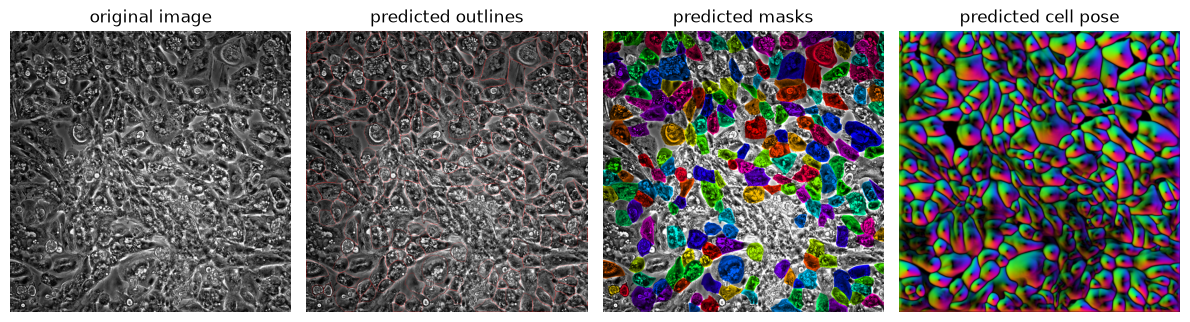

In [5]:
selected_channels = []
for i, c in enumerate([first_channel, second_channel, third_channel]):
  if c == 'None':
    continue
  if int(c) > img.shape[-1]:
    assert False, 'invalid channel index, must have index greater or equal to the number of channels'
  if c != 'None':
    selected_channels.append(int(c))

img_selected_channels = np.zeros_like(img)
if len(selected_channels) == 0:
  img_selected_channels = img
else:
  img_selected_channels[:, :, :len(selected_channels)] = img[:, :, selected_channels]


flow_threshold = 0.4
cellprob_threshold = 0
tile_norm_blocksize = 0

masks, flows, styles = model.eval(img_selected_channels, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

fig = plt.figure(figsize=(12,5))
plot.show_segmentation(fig, img_selected_channels, masks, flows[0])
plt.tight_layout()
plt.show()


## Run Cellpose-SAM on folder of images

if you have many large images, you may want to run them as a loop over images



In [10]:
#create white outlines instead of red. RUN BEFORE SEGMENTING
import numpy as np
import cv2
from cellpose import plot, utils

def show_segmentation_white(fig, img, maski, flowi, channels=[0,0], file_name=None):

    ax = fig.add_subplot(1, 4, 1)
    img0 = img.copy()

    if img0.shape[0] < 4:
        img0 = np.transpose(img0, (1, 2, 0))

    if img0.shape[-1] < 3 or img0.ndim < 3:
        img0 = plot.image_to_rgb(img0, channels=channels)
    else:
        if img0.max() <= 50.0:
            img0 = np.uint8(np.clip(img0, 0, 1) * 255)

    ax.imshow(img0)
    ax.set_title("original image")
    ax.axis("off")

    outlines = utils.masks_to_outlines(maski)

    # make outlines thicker
    #kernel = np.ones((3, 3), np.uint8)
    #outlines = cv2.dilate(outlines.astype(np.uint8), kernel, iterations=1)

    overlay = plot.mask_overlay(img0, maski)

    ax = fig.add_subplot(1, 4, 2)

    y, x = np.nonzero(outlines)

    imgout = img0.copy()
    imgout[y, x] = [255, 255, 255]  # white outlines

    ax.imshow(imgout)
    ax.set_title("predicted outlines")
    ax.axis("off")

    ax = fig.add_subplot(1, 4, 3)
    ax.imshow(overlay)
    ax.set_title("predicted masks")
    ax.axis("off")

    ax = fig.add_subplot(1, 4, 4)
    ax.imshow(flowi)
    ax.set_title("predicted cell pose")
    ax.axis("off")

# overwrite Cellpose function
plot.show_segmentation = show_segmentation_white

In [4]:
masks_ext = ".png" if image_ext == ".png" else ".tif"

flow_threshold = 0.8
cellprob_threshold = 0
tile_norm_blocksize = 0

for i in trange(len(files)):
    f = files[i]

    img = io.imread(f)

    masks, flows, styles = model.eval(
        img,
        batch_size=32,
        flow_threshold=flow_threshold,
        cellprob_threshold=cellprob_threshold,
        normalize={"tile_norm_blocksize": tile_norm_blocksize}
    )

    n_before = len(np.unique(masks)) - 1

    # remove every mask with at least one border pixel
    edge_labels = np.unique(np.concatenate([
        masks[0, :],
        masks[-1, :],
        masks[:, 0],
        masks[:, -1]
    ]))

    edge_labels = edge_labels[edge_labels > 0]

    masks_clean = masks.copy()

    for lbl in edge_labels:
        masks_clean[masks_clean == lbl] = 0

    _, masks_clean = np.unique(masks_clean, return_inverse=True)
    masks = masks_clean.reshape(masks.shape).astype(np.int16)

    n_after = len(np.unique(masks)) - 1

    print(
        f"{f.name}: "
        f"{n_before} masks -> {n_after} masks "
        f"({n_before - n_after} masks at the edges removed)"
    )

    #visualize the segmentation results
    # fig = plt.figure(figsize=(12, 5))
    #plot.show_segmentation(fig, img, masks, flows[0])
    #plt.suptitle(f"{f.name}")
    #plt.tight_layout()
    #plt.show()

    io.imsave(outputdir / (f.stem + "_masks" + masks_ext), masks)

print("done")

  0%|          | 0/21 [00:00<?, ?it/s]c:\Users\20223228\.conda\envs\cellposesam\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),
  5%|▍         | 1/21 [01:30<30:10, 90.51s/it]

m1_plate2_PointA4_R04_im_Composite_PC_DAPI_Seq0227_Dapi_8bit.tif: 610 masks -> 607 masks (3 masks at the edges removed)


 10%|▉         | 2/21 [03:00<28:33, 90.19s/it]

m1_plate2_PointA4_R05_im_Composite_PC_DAPI_Seq0230_Dapi_8bit.tif: 608 masks -> 606 masks (2 masks at the edges removed)


 14%|█▍        | 3/21 [04:29<26:49, 89.43s/it]

...

m1_plate2_PointA5_R10_im_Composite_PC_DAPI_Seq0209_Dapi_8bit.tif: 453 masks -> 446 masks (7 masks at the edges removed)


 95%|█████████▌| 20/21 [30:07<01:30, 90.40s/it]

m1_plate2_PointA5_R11_im_Composite_PC_DAPI_Seq0212_Dapi_8bit.tif: 429 masks -> 426 masks (3 masks at the edges removed)


100%|██████████| 21/21 [31:37<00:00, 90.36s/it]

m1_plate2_PointA5_R12_im_Composite_PC_DAPI_Seq0215_Dapi_8bit.tif: 502 masks -> 498 masks (4 masks at the edges removed)
done


if you have small images, you may want to load all of them first and then run, so that they can be batched together on the GPU

In [11]:
#without plotting segmentation results
masks_ext = ".png" if image_ext == ".png" else ".tif"

flow_threshold = 0.8
cellprob_threshold = 0
tile_norm_blocksize = 0

print("loading images")
imgs = [io.imread(files[i]) for i in trange(len(files))]

print("running cellpose model")
masks, flows, styles = model.eval(imgs, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

cleaned_masks = []

for f, mask in zip(files, masks):

    n_before = len(np.unique(mask)) - 1
    
    # remove every mask with at least one border pixel
    edge_labels = np.unique(np.concatenate([
        mask[0, :],
        mask[-1, :],
        mask[:, 0],
        mask[:, -1]
    ]))

    edge_labels = edge_labels[edge_labels > 0]

    masks_clean = mask.copy()

    for lbl in edge_labels:
        masks_clean[masks_clean == lbl] = 0

    _, masks_clean = np.unique(masks_clean, return_inverse=True)
    masks = masks_clean.reshape(mask.shape).astype(np.int16)

    n_after = len(np.unique(masks)) - 1

    print(
        f"{f.name}: "
        f"{n_before} masks -> {n_after} masks "
        f"({n_before - n_after} masks at the edges removed)"
    )

    cleaned_masks.append(masks)

    io.imsave(outputdir / f"{f.stem}_without_edge_masks{masks_ext}", masks)


loading images


100%|██████████| 1/1 [00:00<00:00, 14.91it/s]

running cellpose model


m0_plate2_PointA5_R02_im_Composite_PC_DAPI_Seq0185_Dapi_8bit.tif: 951 masks -> 949 masks (2 masks at the edges removed)


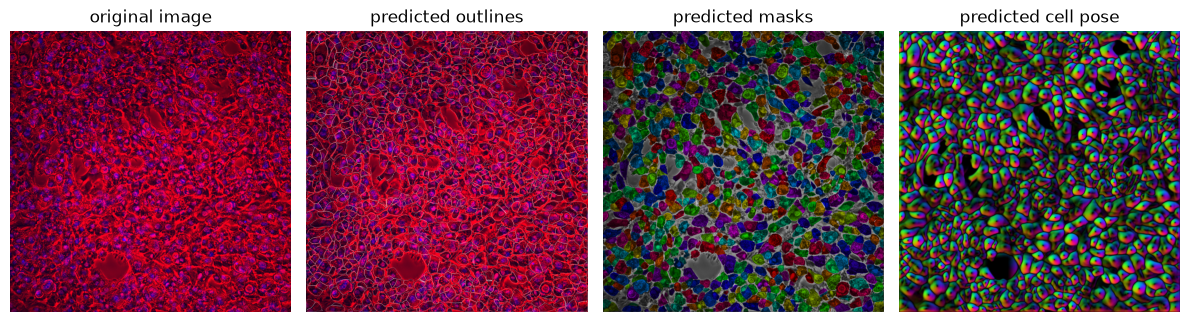

In [12]:
#Visualization of the segmentation results

for f, img, mask, flow in zip(files, imgs, cleaned_masks, flows):

    fig = plt.figure(figsize=(12,5))

    plot.show_segmentation(fig, img, mask, flow[0])

    plt.tight_layout()

    plt.savefig(
        outputdir / f"{f.stem}_segmentation_cleaned.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)